# Separando a Fumaça na Imagem com o SAM 2

Neste projeto, foi utilizado o SAM 2 para separar (segmentar) a fumaça do resto da imagem de uma rodovia.

Foram feitos 6 testes dando dicas diferentes para a IA (como desenhar uma caixa em volta da fumaça ou apontar locais específicos) e comparando os resultados com um gabarito manualmente definido.

**Testes feitos:**

| Teste | Dica de Caixa | Pontos Positivos (Aqui tem fumaça) | Pontos Negativos (Aqui não tem fumaça) |
|---|---|---|---|
| **A** (antigo) | Caixa do YOLO | 1 | 0 |
| **B** (antigo) | Caixa do YOLO | 2 | 0 |
| **C** (antigo) | Caixa do YOLO | 2 | 1 |
| **D** (novo) | Caixa ajustada | 1 | 0 |
| **E** (novo) | Caixa ajustada | 3 | 0 |
| **F** (novo) | Caixa ajustada | 3 | 5 |

## 1. Preparando o Ambiente
Aqui são instaladas as dependências.

In [19]:
%pip -q install ultralytics opencv-python requests matplotlib pandas gdown scikit-image scipy

## 2. Ferramentas e Configurações Iniciais

In [20]:
import os
import base64
import subprocess
import sys

import requests
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from IPython.display import display, Markdown
from scipy import ndimage as ndi
from skimage.filters import threshold_multiotsu

ROBOFLOW_URL = (
    "https://serverless.roboflow.com/gustavo-cassiolato-unifesp-br/"
    "workflows/smoke-plume-from-chimney-vsmoke-plume-from-chimney-tu9hz-2-yolo26s-t1-logic"
)

# Chave da API: tenta pegar dos Secrets do Colab. Se não tiver, usa a do notebook-base.
# Cuidado: não deixe a chave no código se for publicar o repositório.
def get_api_key():
    try:
        from google.colab import userdata
        key = userdata.get("ROBOFLOW_API_KEY")
        if key:
            return key
    except Exception:
        pass
    return os.environ.get("ROBOFLOW_API_KEY", "")

ROBOFLOW_API_KEY = get_api_key() or "gNXCLqpCZidjLllGlu7Q"

IMAGE_PATH = "Pluma_Imagem.jpeg"
GOOGLE_DRIVE_FILE_ID = "1T9D1xFLDr1XFwjyHdYgVCUq5JCvK5pzD"

# Caixa que a API devolveu para essa imagem (em fração da largura/altura).
# Só é usada se a API falhar.
FALLBACK_BBOX_FRAC = (0.036, 0.0, 0.878, 0.44)

N_POS = 3        # pontos positivos automáticos
N_NEG = 5        # pontos negativos automáticos
BOX_PAD = 0.015  # folga da caixa justa

RESULTS_DIR = "resultados_segmentacao_pluma"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Pronto.")

Pronto.


## 3. Carregando a Imagem
A foto que será analizada é baixada.

Imagem: 1200 x 1600 pixels


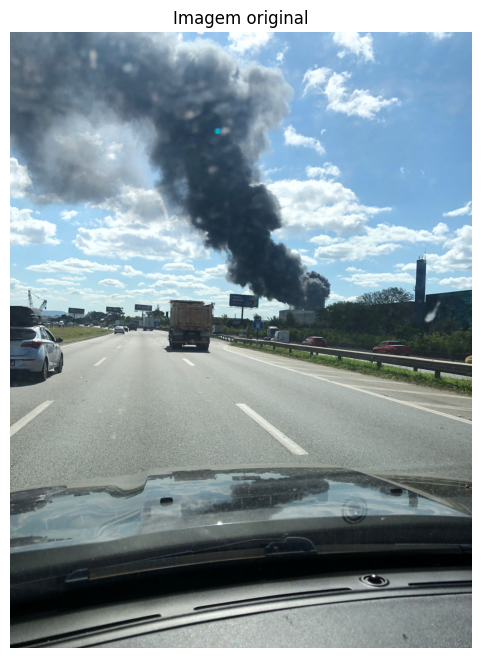

In [21]:
if not os.path.exists(IMAGE_PATH):
    subprocess.run(
        [sys.executable, "-m", "gdown", f"https://drive.google.com/uc?id={GOOGLE_DRIVE_FILE_ID}", "-O", IMAGE_PATH],
        check=True
    )

img_pil = Image.open(IMAGE_PATH).convert("RGB")
image = np.asarray(img_pil)
HEIGHT, WIDTH = image.shape[:2]

print(f"Imagem: {WIDTH} x {HEIGHT} pixels")
plt.figure(figsize=(6, 8))
plt.imshow(image)
plt.title("Imagem original")
plt.axis("off")
plt.show()

## 4. Encontrando a Fumaça (YOLO)
Usando um modelo pronto chamado YOLO para achar a região geral da fumaça. Ele desenha uma "caixa" em volta dela, que será utilizada nos testes A, B e C.

In [22]:
def extract_predictions(api_result):
    for output in api_result.get("outputs", []):
        block = output.get("predictions", {})
        if isinstance(block, dict):
            preds = block.get("predictions", [])
            if isinstance(preds, list) and preds:
                return preds
    return []

try:
    with open(IMAGE_PATH, "rb") as f:
        image_b64 = base64.b64encode(f.read()).decode("utf-8")
    headers = {"Content-Type": "application/json", "Authorization": f"Bearer {ROBOFLOW_API_KEY}"}
    payload = {"inputs": {"image": {"type": "base64", "value": image_b64}}}
    response = requests.post(ROBOFLOW_URL, json=payload, headers=headers, timeout=120)
    response.raise_for_status()
    predictions = extract_predictions(response.json())
    if not predictions:
        raise ValueError("A API não retornou detecções.")
    pred = max(predictions, key=lambda p: float(p.get("confidence", 0)))
    xc, yc, wb, hb = (float(pred[k]) for k in ("x", "y", "width", "height"))
    x1, y1, x2, y2 = xc - wb / 2, yc - hb / 2, xc + wb / 2, yc + hb / 2
    print(f"Detecção da API. Confiança: {float(pred.get('confidence', 0)):.1%}")
except Exception as exc:
    fx1, fy1, fx2, fy2 = FALLBACK_BBOX_FRAC
    x1, y1, x2, y2 = fx1 * WIDTH, fy1 * HEIGHT, fx2 * WIDTH, fy2 * HEIGHT
    print("API indisponível, usando a caixa de fallback.", exc)

x1 = float(np.clip(x1, 0, WIDTH - 1)); y1 = float(np.clip(y1, 0, HEIGHT - 1))
x2 = float(np.clip(x2, x1 + 1, WIDTH)); y2 = float(np.clip(y2, y1 + 1, HEIGHT))
w_box, h_box = x2 - x1, y2 - y1
x_center, y_center = (x1 + x2) / 2, (y1 + y2) / 2
YOLO_BOX = [x1, y1, x2, y2]
print("Caixa YOLO:", [round(v) for v in YOLO_BOX])

Detecção da API. Confiança: 76.1%
Caixa YOLO: [43, 0, 1054, 704]


## 5. Funções de Ajuda
Como a cor da fumaça e das nuvens são parecidas (tudo parece meio azulado), será utilziado do **brilho** (claro e escuro) para diferenciá-las.

In [23]:
def odd_kernel(frac, shape):
    # tamanho de kernel ímpar, proporcional ao tamanho da imagem
    n = max(3, int(round(frac * max(shape[:2]))))
    return n if n % 2 == 1 else n + 1

def to_value(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)[..., 2]

def box_mask(shape, box):
    m = np.zeros(shape[:2], bool)
    bx1, by1, bx2, by2 = [int(round(v)) for v in box]
    m[max(by1, 0):by2, max(bx1, 0):bx2] = True
    return m

def bright_threshold(V, roi):
    # acha o brilho que separa fumaça de céu/nuvem (vale do histograma)
    vals = V[roi]
    t_low = float(threshold_multiotsu(vals, classes=3)[0])
    hist, edges = np.histogram(vals, bins=64, range=(0, 256))
    hist = np.convolve(hist, np.ones(3) / 3, mode="same")
    centers = (edges[:-1] + edges[1:]) / 2
    upper = centers > t_low
    peak = centers[upper][np.argmax(hist[upper])]
    seg = (centers >= t_low) & (centers <= peak)
    return float(centers[seg][np.argmin(hist[seg])]), float(peak), t_low

def refine_mask(mask, V, T, anchors_xy, min_hole_frac=0.002):
    # limpa a máscara: tira pixels claros (céu/nuvem), remove ruído,
    # fica só com a parte ligada aos pontos positivos e fecha buracos pequenos
    H, W = mask.shape
    k = odd_kernel(0.0055, mask.shape)
    m = (mask & (V < T)).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * k + 1, 2 * k + 1)))
    lab, n = ndi.label(m)
    keep = np.zeros(m.shape, bool)
    for x, y in anchors_xy:
        l = lab[int(np.clip(y, 0, H - 1)), int(np.clip(x, 0, W - 1))]
        if l > 0:
            keep |= lab == l
    if not keep.any() and n > 0:
        keep = lab == (1 + int(np.argmax(ndi.sum(m, lab, range(1, n + 1)))))
    holes = ndi.binary_fill_holes(keep) & ~keep
    hl, hn = ndi.label(holes)
    for i in range(1, hn + 1):
        if (hl == i).sum() < min_hole_frac * H * W:
            keep |= hl == i
    return keep

def tight_box(mask, pad_frac=BOX_PAD):
    # menor caixa que cobre a máscara
    H, W = mask.shape
    ys, xs = np.where(mask)
    px, py = pad_frac * W, pad_frac * H
    return [float(max(0, xs.min() - px)), float(max(0, ys.min() - py)),
            float(min(W - 1, xs.max() + px)), float(min(H - 1, ys.max() + py))]

def farthest_point_sampling(cands_xy, first_xy, k):
    # escolhe k pontos bem espalhados
    chosen = [np.asarray(first_xy, float)]
    while len(chosen) < k:
        d = np.min(np.linalg.norm(cands_xy[:, None, :] - np.array(chosen)[None], axis=2), axis=1)
        chosen.append(cands_xy[int(np.argmax(d))].astype(float))
    return [(float(p[0]), float(p[1])) for p in chosen]

def pick_positives(smoke_mask, k=N_POS, rel=0.30):
    # pontos bem dentro da fumaça e espalhados
    dt = ndi.distance_transform_edt(smoke_mask)
    cand = np.argwhere(dt >= rel * dt.max())[:, ::-1]
    first = np.array(np.unravel_index(np.argmax(dt), dt.shape))[::-1]
    return farthest_point_sampling(cand, first, k)

def pick_negatives(V, T, box, smoke_mask, k=N_NEG, rel=0.30):
    # pontos no meio de regiões claras (céu/nuvem) dentro da caixa, longe da fumaça
    H, W = V.shape
    bright = (V >= T) & box_mask(V.shape, box)
    kk = odd_kernel(0.0076, V.shape)
    bright = cv2.morphologyEx(bright.astype(np.uint8), cv2.MORPH_OPEN,
                              cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kk, kk))).astype(bool)
    bright &= ndi.distance_transform_edt(~smoke_mask) > 0.02 * max(H, W)
    dt = ndi.distance_transform_edt(np.pad(bright, 1))[1:-1, 1:-1]
    if dt.max() == 0:
        return []
    cand = np.argwhere(dt >= rel * dt.max())[:, ::-1]
    first = np.array(np.unravel_index(np.argmax(dt), dt.shape))[::-1]
    return farthest_point_sampling(cand, first, k)

def clamp_point(p):
    return [float(np.clip(p[0], 0, WIDTH - 1)), float(np.clip(p[1], 0, HEIGHT - 1))]

print("Funções definidas.")

Funções definidas.


## 6. Analisando o Brilho da Imagem
Vamos descobrir qual nível de brilho separa exatamente a fumaça (mais escura) do céu e das nuvens (mais claros) dentro daquela caixa que o YOLO achou.

Limiar de brilho céu/nuvem: V >= 202
57% da caixa do YOLO é céu ou nuvem.


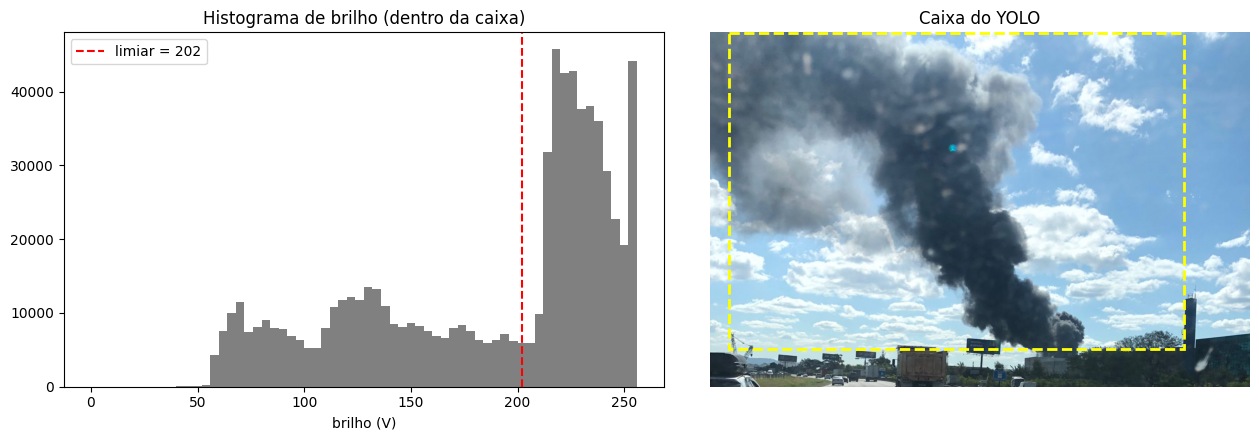

In [24]:
V = to_value(image)
roi_yolo = box_mask(image.shape, YOLO_BOX)
T_BRIGHT, V_PEAK, T_DARK = bright_threshold(V, roi_yolo)

print(f"Limiar de brilho céu/nuvem: V >= {T_BRIGHT:.0f}")
print(f"{100 * (V[roi_yolo] >= T_BRIGHT).mean():.0f}% da caixa do YOLO é céu ou nuvem.")

VIEW_Y = int(min(HEIGHT, 1.12 * y2))   # recorte para mostrar só a parte de cima

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(V[roi_yolo].ravel(), bins=64, range=(0, 256), color="gray")
axes[0].axvline(T_BRIGHT, color="r", ls="--", label=f"limiar = {T_BRIGHT:.0f}")
axes[0].set_title("Histograma de brilho (dentro da caixa)")
axes[0].set_xlabel("brilho (V)"); axes[0].legend()
axes[1].imshow(image[:VIEW_Y])
axes[1].add_patch(patches.Rectangle((x1, y1), w_box, h_box, lw=2, ec="yellow", fc="none", ls="--"))
axes[1].set_title("Caixa do YOLO"); axes[1].axis("off")
plt.tight_layout(); plt.show()

## 7. Criando o Gabarito (Referência)
Para sabermos se a Inteligência Artificial acertou, precisamos de um gabarito. Por isso, desenhamos um contorno vermelho na mão em volta da fumaça verdadeira.

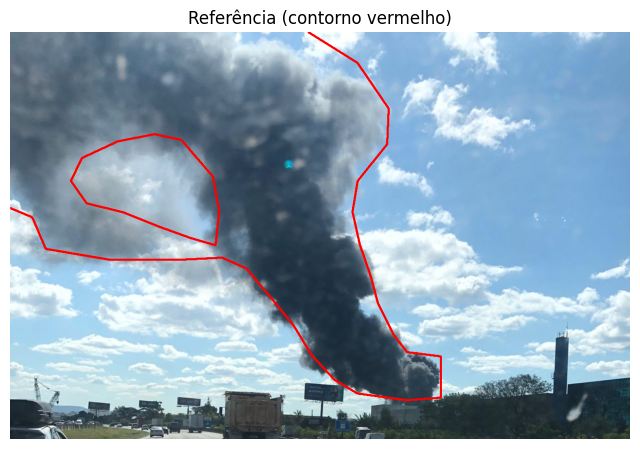

In [25]:
REF_POLY_FRAC = [
    (0.000, 0.000), (0.480, 0.000), (0.560, 0.038), (0.610, 0.093), (0.608, 0.136), (0.560, 0.180),
    (0.552, 0.218), (0.564, 0.257), (0.581, 0.295), (0.593, 0.328), (0.618, 0.366), (0.640, 0.388),
    (0.695, 0.393), (0.695, 0.442), (0.640, 0.445), (0.560, 0.437), (0.523, 0.420), (0.487, 0.391),
    (0.458, 0.355), (0.422, 0.322), (0.381, 0.286), (0.342, 0.273), (0.276, 0.275), (0.160, 0.275),
    (0.058, 0.262), (0.036, 0.224), (0.000, 0.213),
]
# abertura (céu/nuvem no meio da fumaça) que é tirada do polígono
REF_HOLES_FRAC = [[
    (0.276, 0.131), (0.327, 0.175), (0.337, 0.218), (0.331, 0.258), (0.291, 0.249), (0.240, 0.235),
    (0.182, 0.218), (0.124, 0.207), (0.099, 0.180), (0.116, 0.153), (0.174, 0.133), (0.233, 0.124),
]]

ref_u8 = np.zeros((HEIGHT, WIDTH), np.uint8)
cv2.fillPoly(ref_u8, [np.array([[x * WIDTH, y * HEIGHT] for x, y in REF_POLY_FRAC], np.int32)], 1)
for hole in REF_HOLES_FRAC:
    cv2.fillPoly(ref_u8, [np.array([[x * WIDTH, y * HEIGHT] for x, y in hole], np.int32)], 0)
ref = ref_u8.astype(bool)

plt.figure(figsize=(8, 5.5))
plt.imshow(image[:VIEW_Y])
plt.contour(ref[:VIEW_Y].astype(float), levels=[0.5], colors=["red"], linewidths=1.5)
plt.title("Referência (contorno vermelho)"); plt.axis("off"); plt.show()

## 8. Testes Iniciais com o SAM 2 (A, B e C)
Agora vamos testar o modelo SAM 2 usando as primeiras dicas escolhidas.

In [26]:
from ultralytics import SAM
sam_model = SAM("sam2.1_b.pt")

def run_sam(box, pos_points, neg_points=()):
    # roda o SAM 2 com a caixa e os pontos (positivo = 1, negativo = 0)
    pts = list(pos_points) + list(neg_points)
    lbl = [1] * len(pos_points) + [0] * len(neg_points)
    res = sam_model.predict(
        source=img_pil,
        bboxes=[float(v) for v in box],
        points=[[list(map(float, p)) for p in pts]],
        labels=[lbl],
        verbose=False,
    )
    if not res or res[0].masks is None or len(res[0].masks.data) == 0:
        raise RuntimeError("O SAM 2 não retornou máscara.")
    m = res[0].masks.data[0].detach().cpu().numpy()
    if m.shape != (HEIGHT, WIDTH):
        m = cv2.resize(m.astype(np.uint8), (WIDTH, HEIGHT), interpolation=cv2.INTER_NEAREST)
    return m.astype(bool)

positive_1 = clamp_point([x_center, y_center])
positive_2 = clamp_point([x1 + 0.42 * w_box, y1 + 0.32 * h_box])
negative_1 = clamp_point([x1 + 0.92 * w_box, y1 + 0.56 * h_box])

CONFIGS = {
    "A": dict(label="A: YOLO + 1 positivo",               box=YOLO_BOX, pos=[positive_1],             neg=[]),
    "B": dict(label="B: YOLO + 2 positivos",              box=YOLO_BOX, pos=[positive_1, positive_2], neg=[]),
    "C": dict(label="C: YOLO + 2 positivos + 1 negativo", box=YOLO_BOX, pos=[positive_1, positive_2], neg=[negative_1]),
}

masks_raw = {}
for key in ["A", "B", "C"]:
    cfg = CONFIGS[key]
    masks_raw[key] = run_sam(cfg["box"], cfg["pos"], cfg["neg"])
    print(f"{cfg['label']:<36s} pixels: {int(masks_raw[key].sum()):>9,}")

A: YOLO + 1 positivo                 pixels:   307,875
B: YOLO + 2 positivos                pixels:   584,543
C: YOLO + 2 positivos + 1 negativo   pixels:   508,737


## 9. Tentando Novas Dicas (D, E e F)
As dicas antigas tinham problemas:
1. A caixa era muito grande e pegava muito céu.
2. O ponto que dizia "aqui não tem fumaça" estava no lugar errado.
3. Os pontos que diziam "aqui tem fumaça" estavam muito perto um do outro.

Para consertar, será utilizada uma **caixa menor e mais apertada** e espalhar melhor os nossos pontos de dica.

Largura da caixa: YOLO 84% -> justa 71% da imagem
Positivos: [(185, 61), (730, 656), (655, 177)]
Negativos: [(286, 585), (811, 35), (811, 548), (35, 474), (734, 292)]


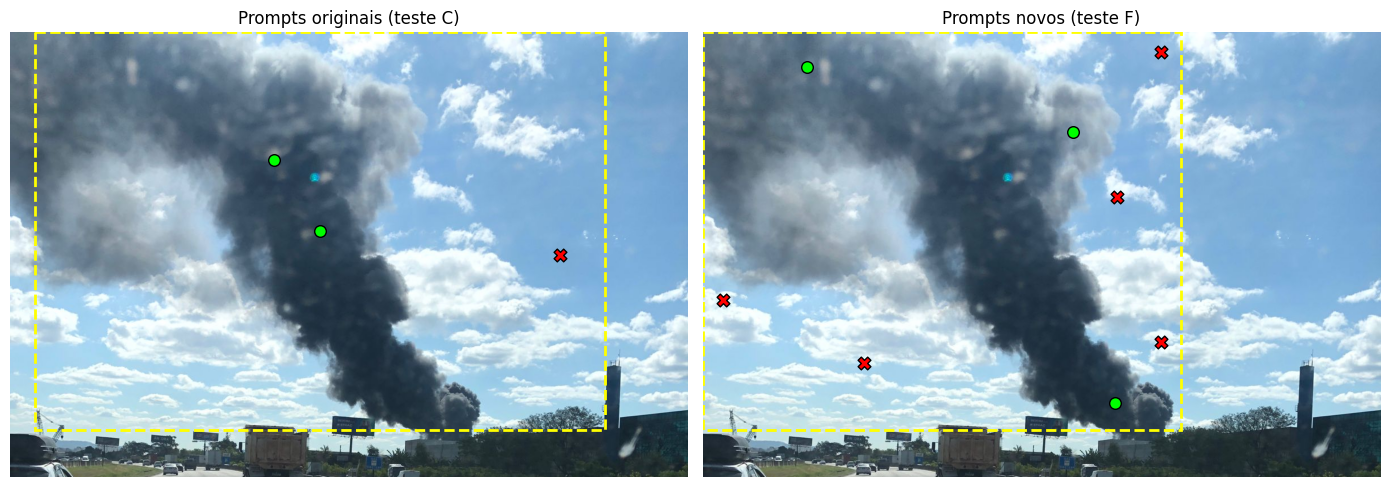

In [27]:
A_clean = refine_mask(masks_raw["A"], V, T_BRIGHT, anchors_xy=[positive_1])

box_tight = tight_box(A_clean)
box_tight[3] = min(box_tight[3], y2)    # não passa do horizonte
pos_auto = pick_positives(A_clean, N_POS)
neg_auto = pick_negatives(V, T_BRIGHT, box_tight, A_clean, N_NEG)

print(f"Largura da caixa: YOLO {100 * w_box / WIDTH:.0f}% -> justa {100 * (box_tight[2] - box_tight[0]) / WIDTH:.0f}% da imagem")
print("Positivos:", [(round(x), round(y)) for x, y in pos_auto])
print("Negativos:", [(round(x), round(y)) for x, y in neg_auto])

CONFIGS["D"] = dict(label="D: caixa justa + 1 positivo",               box=box_tight, pos=pos_auto[:1], neg=[])
CONFIGS["E"] = dict(label="E: caixa justa + 3 positivos",              box=box_tight, pos=pos_auto,     neg=[])
CONFIGS["F"] = dict(label="F: caixa justa + 3 positivos + negativos",  box=box_tight, pos=pos_auto,     neg=neg_auto)

def draw_prompts(ax, cfg, s=70):
    bx1, by1, bx2, by2 = cfg["box"]
    ax.add_patch(patches.Rectangle((bx1, by1), bx2 - bx1, by2 - by1, lw=2, ec="yellow", fc="none", ls="--"))
    if cfg["pos"]:
        px, py = zip(*cfg["pos"]); ax.scatter(px, py, s=s, c="lime", edgecolors="k", marker="o", zorder=5)
    if cfg["neg"]:
        nx, ny = zip(*cfg["neg"]); ax.scatter(nx, ny, s=s * 1.2, c="red", edgecolors="k", marker="X", zorder=5)

# confere se os positivos (verde) estão na fumaça e os negativos (vermelho) no fundo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(image[:VIEW_Y]); draw_prompts(axes[0], CONFIGS["C"]); axes[0].set_title("Prompts originais (teste C)")
axes[1].imshow(image[:VIEW_Y]); draw_prompts(axes[1], CONFIGS["F"]); axes[1].set_title("Prompts novos (teste F)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig0_prompts.png"), dpi=150, bbox_inches="tight"); plt.show()

In [28]:
for key in ["D", "E", "F"]:
    cfg = CONFIGS[key]
    masks_raw[key] = run_sam(cfg["box"], cfg["pos"], cfg["neg"])
    print(f"{cfg['label']:<42s} pixels: {int(masks_raw[key].sum()):>9,}")

D: caixa justa + 1 positivo                pixels:   322,559
E: caixa justa + 3 positivos               pixels:   324,981
F: caixa justa + 3 positivos + negativos   pixels:   297,351


## 10. Limpando as Máscaras
O resultado da IA pode vir levemente errado. Por isso será aplicado um filtro para limpar o resultado, que tentará:
- Tirar os pedaços muito claros (que são céu ou nuvem).
- Remover pontinhos soltos (ruído).
- Fechar buracos no meio da fumaça.

In [29]:
masks_ref = {key: refine_mask(masks_raw[key], V, T_BRIGHT, anchors_xy=CONFIGS[key]["pos"]) for key in CONFIGS}
for key in CONFIGS:
    print(f"{key}: {int(masks_raw[key].sum()):>9,} px (bruta) -> {int(masks_ref[key].sum()):>9,} px (limpa)")

A:   307,875 px (bruta) ->   295,258 px (limpa)
B:   584,543 px (bruta) ->   310,330 px (limpa)
C:   508,737 px (bruta) ->   310,242 px (limpa)
D:   322,559 px (bruta) ->   303,837 px (limpa)
E:   324,981 px (bruta) ->   303,201 px (limpa)
F:   297,351 px (bruta) ->   288,533 px (limpa)


## 11. Comparação Visual
As imagens abaixos mostram:
1. A foto com as dicas.
2. A silhueta da fumaça achada (preto e branco).
3. A fumaça colorida em cima da foto.
4. Os erros: **Verde** = Acertou / **Vermelho** = Achou que era fumaça, mas não era / **Azul** = Era fumaça, mas a IA deixou passar.

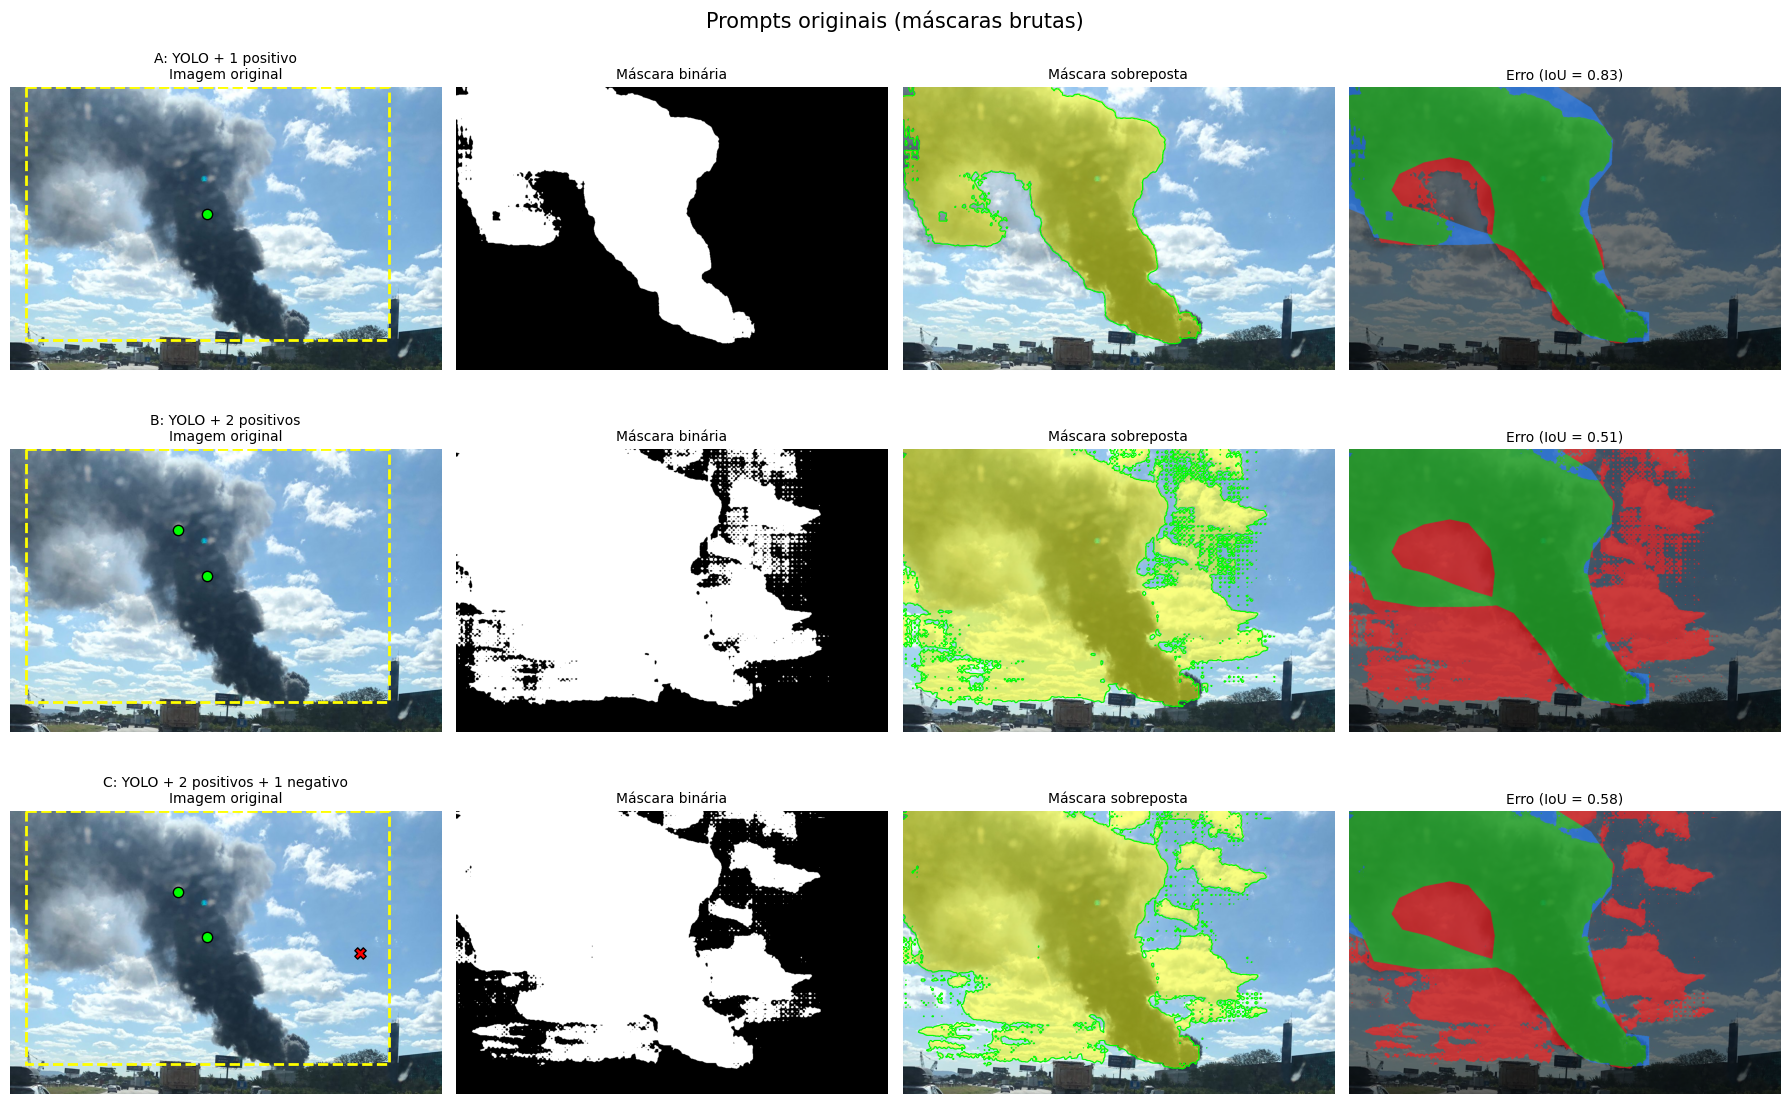

In [30]:
def error_overlay(mask):
    base = image.astype(np.float32) * 0.45
    out = base.copy()
    for m, col in [(mask & ref, (40, 200, 40)), (mask & ~ref, (255, 30, 30)), (~mask & ref, (40, 130, 255))]:
        out[m] = 0.35 * base[m] + 0.65 * np.array(col, np.float32)
    return out.clip(0, 255).astype(np.uint8)

def plot_rows(keys, masks, title, filename):
    fig, axes = plt.subplots(len(keys), 4, figsize=(18, 3.9 * len(keys)))
    axes = np.atleast_2d(axes)
    for r, key in enumerate(keys):
        m = masks[key]
        axes[r, 0].imshow(image[:VIEW_Y]); draw_prompts(axes[r, 0], CONFIGS[key], s=55)
        axes[r, 0].set_title(f"{CONFIGS[key]['label']}\nImagem original", fontsize=10)
        axes[r, 1].imshow(m[:VIEW_Y], cmap="gray", vmin=0, vmax=1); axes[r, 1].set_title("Máscara binária", fontsize=10)
        axes[r, 2].imshow(image[:VIEW_Y])
        axes[r, 2].imshow(np.ma.masked_where(~m[:VIEW_Y], m[:VIEW_Y]), cmap="autumn", alpha=0.5, vmin=0, vmax=1)
        if m.any() and (~m).any():
            axes[r, 2].contour(m[:VIEW_Y].astype(float), levels=[0.5], colors=["lime"], linewidths=0.8)
        axes[r, 2].set_title("Máscara sobreposta", fontsize=10)
        iou = (m & ref).sum() / (m | ref).sum()
        axes[r, 3].imshow(error_overlay(m)[:VIEW_Y]); axes[r, 3].set_title(f"Erro (IoU = {iou:.2f})", fontsize=10)
        for c in range(4): axes[r, c].axis("off")
    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename), dpi=150, bbox_inches="tight"); plt.show()

plot_rows(["A", "B", "C"], masks_raw, "Prompts originais (máscaras brutas)", "fig1_originais.png")

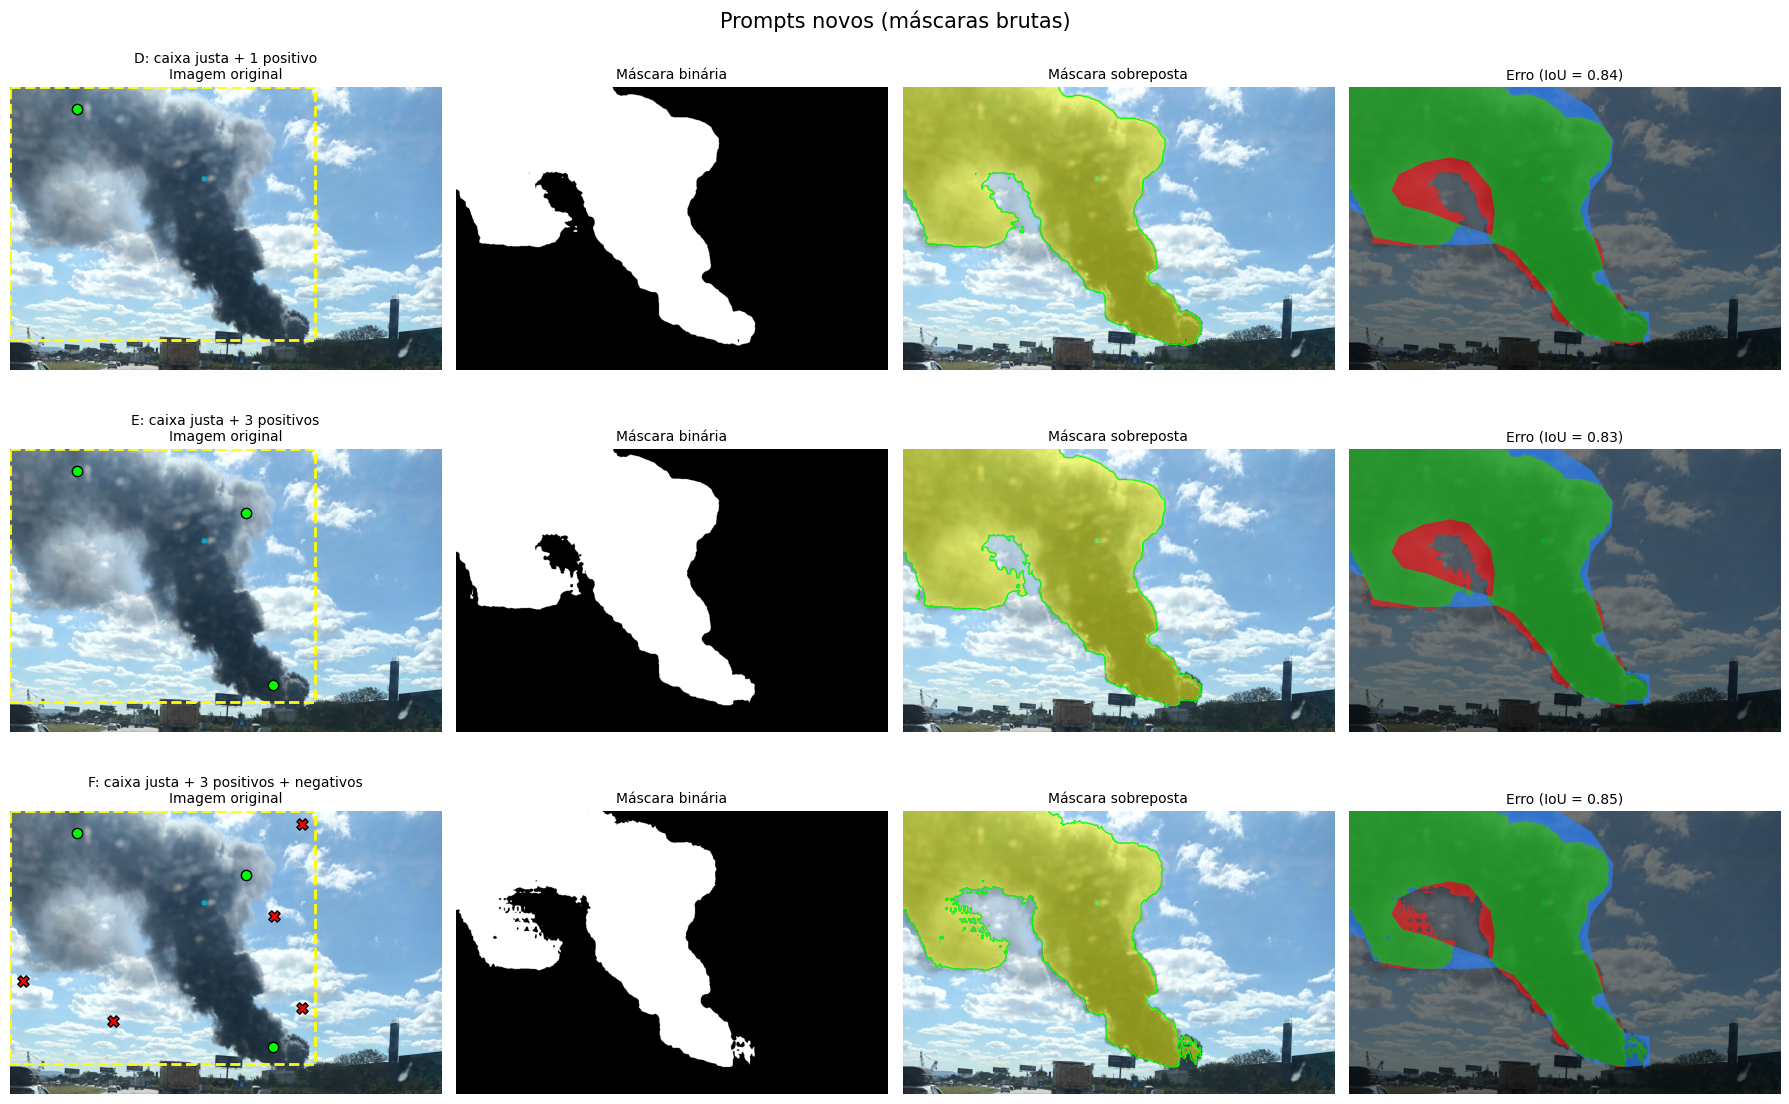

In [31]:
plot_rows(["D", "E", "F"], masks_raw, "Prompts novos (máscaras brutas)", "fig2_novos.png")

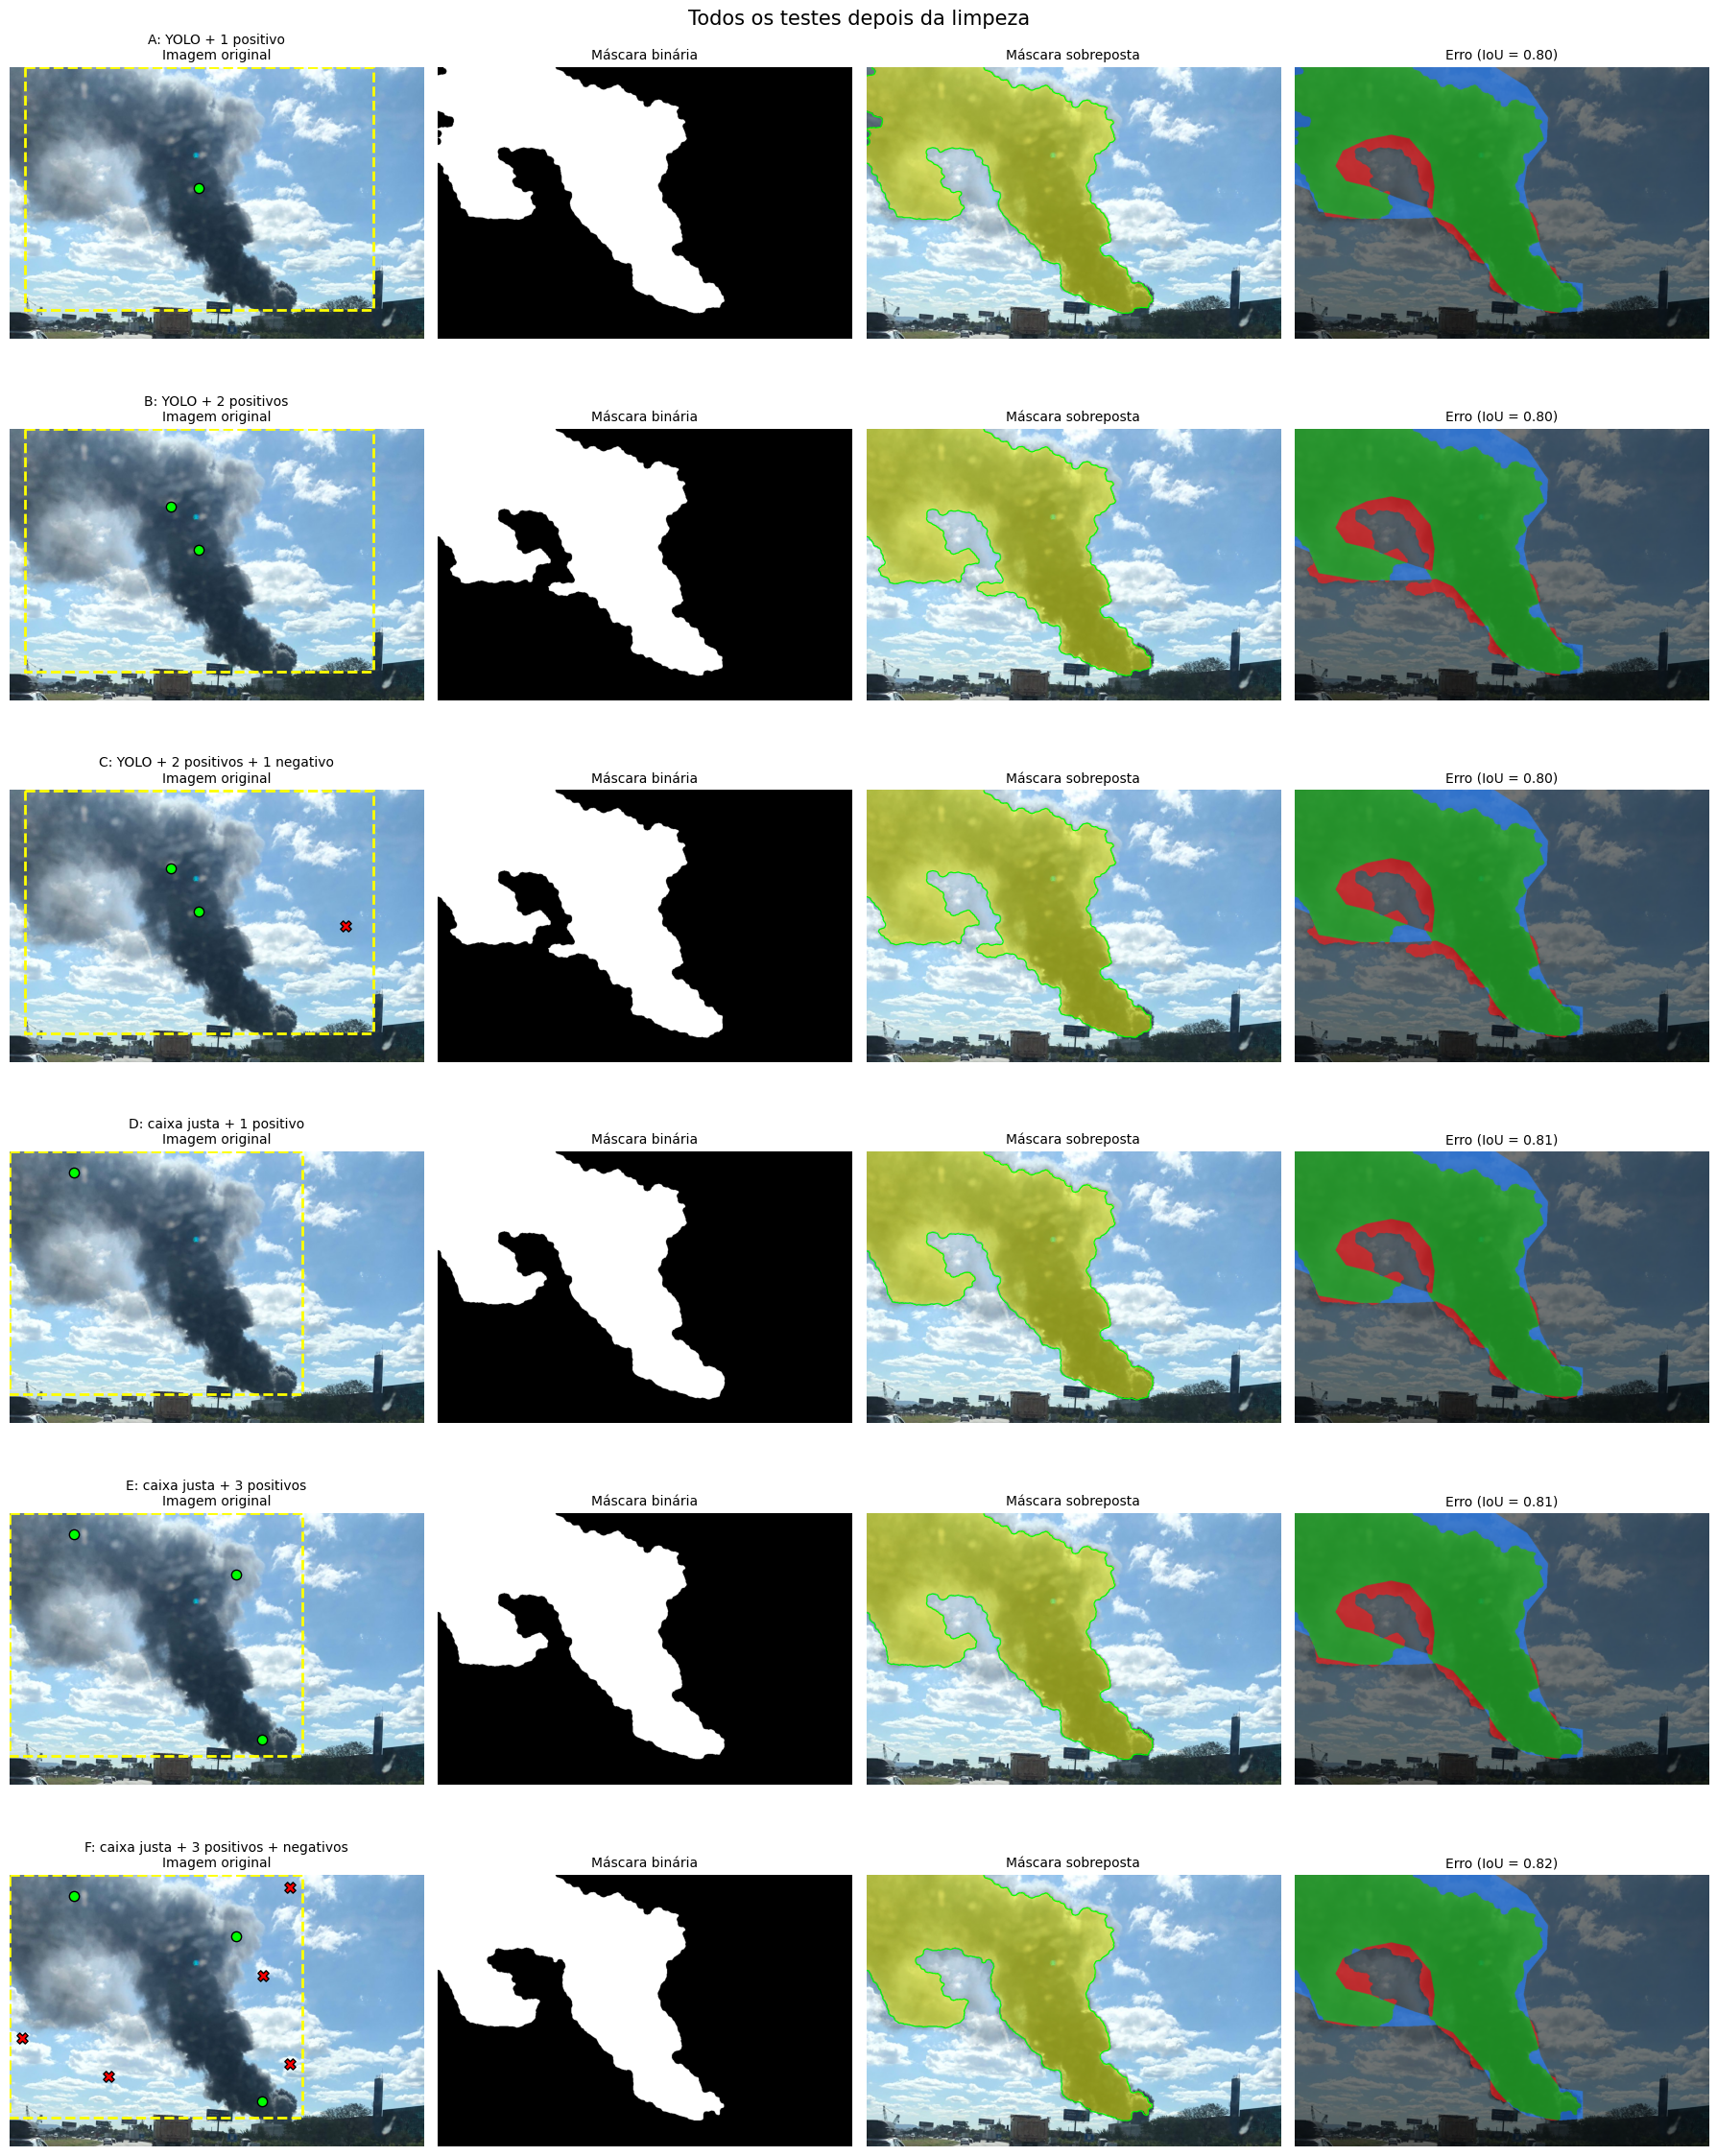

In [32]:
plot_rows(["A", "B", "C", "D", "E", "F"], masks_ref, "Todos os testes depois da limpeza", "fig3_limpas.png")

## 12. Notas do Modelo (Métricas)
Como medir qual foi melhor?
- **IoU:** É a nota geral de sobreposição. (1 = perfeito).
- **Precisão:** De tudo que o modelo disse que era fumaça, quanto ele acertou?
- **Recall:** Da fumaça que existia de verdade, quanto o modelo conseguiu achar?

,teste,variante,IoU,Precisão,Recall,FP em céu/nuvem (% dos FP),FN (% da referência),FN claros (% dos FN)
0,A,bruta,0.833,0.914,0.904,7.920,9.595,70.258
1,A,limpa,0.804,0.916,0.869,0.887,13.127,81.580
2,B,bruta,0.510,0.517,0.972,87.613,2.821,80.091
3,B,limpa,0.797,0.889,0.886,2.559,11.396,93.461
4,C,bruta,0.578,0.590,0.965,83.379,3.496,83.687
5,C,limpa,0.799,0.890,0.887,2.408,11.319,94.169
6,D,bruta,0.838,0.896,0.928,16.502,7.179,92.664
7,D,limpa,0.813,0.908,0.886,1.278,11.391,93.851
8,E,bruta,0.832,0.889,0.929,21.196,7.144,89.466
9,E,limpa,0.810,0.907,0.884,1.399,11.648,91.804


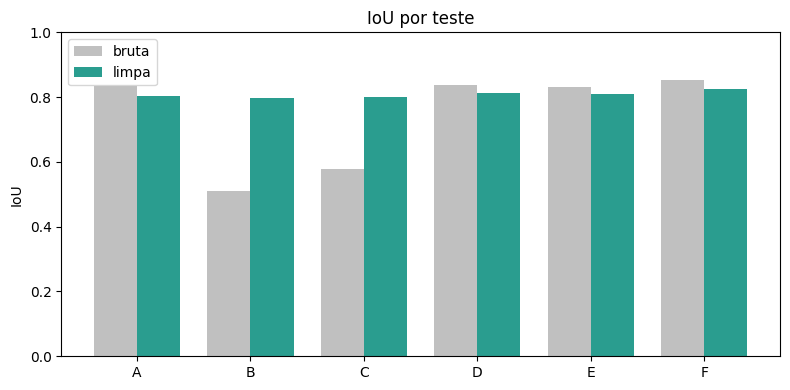

In [33]:
def compute_metrics(mask):
    tp = int((mask & ref).sum()); fp = int((mask & ~ref).sum()); fn = int((~mask & ref).sum())
    fp_bright = int(((mask & ~ref) & (V >= T_BRIGHT)).sum())
    fn_bright = int(((~mask & ref) & (V >= T_BRIGHT)).sum())
    return {
        "IoU": tp / (tp + fp + fn),
        "Precisão": tp / (tp + fp) if tp + fp else 0.0,
        "Recall": tp / (tp + fn) if tp + fn else 0.0,
        "FP em céu/nuvem (% dos FP)": 100 * fp_bright / fp if fp else 0.0,
        "FN (% da referência)": 100 * fn / ref.sum(),
        "FN claros (% dos FN)": 100 * fn_bright / fn if fn else 0.0,
    }

rows = []
for variante, dic in [("bruta", masks_raw), ("limpa", masks_ref)]:
    for key, cfg in CONFIGS.items():
        rows.append({"teste": key, "variante": variante, **compute_metrics(dic[key])})
df = pd.DataFrame(rows).sort_values(["teste", "variante"]).reset_index(drop=True)
display(df.round(3))
df.round(4).to_csv(os.path.join(RESULTS_DIR, "metricas.csv"), index=False, encoding="utf-8-sig")

raw_df, ref_df = df[df.variante == "bruta"].set_index("teste"), df[df.variante == "limpa"].set_index("teste")
keys = list(CONFIGS)
xs = np.arange(len(keys)); w = 0.38
plt.figure(figsize=(8, 4))
plt.bar(xs - w / 2, [raw_df.loc[k, "IoU"] for k in keys], w, label="bruta", color="#c0c0c0")
plt.bar(xs + w / 2, [ref_df.loc[k, "IoU"] for k in keys], w, label="limpa", color="#2a9d8f")
plt.xticks(xs, keys); plt.ylim(0, 1); plt.ylabel("IoU"); plt.title("IoU por teste"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig4_iou.png"), dpi=150); plt.show()

## 13. Por que o modelo se confunde?
Aqui fazemos um teste rápido verificando as cores e o brilho. Descobrimos que existem pedaços da fumaça que são tão claros quanto as nuvens, o que confunde a IA.

In [34]:
BR = image[..., 2].astype(float) - image[..., 0].astype(float)    # azul - vermelho

zone = box_mask(image.shape, box_tight)
k = odd_kernel(0.012, image.shape)
kern = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
bg = zone & ~cv2.dilate(ref.astype(np.uint8), kern).astype(bool)   # fundo dentro da caixa justa
sky = bg & (BR > 70)
cloud = bg & (V >= T_BRIGHT) & ~(BR > 70)

regioes = {"fumaça (núcleo escuro)": ref & (V < T_DARK), "fumaça (parte clara)": ref & (V >= T_DARK),
           "nuvem": cloud, "céu": sky}
tabela = [{"região": n, "brilho médio": V[m].mean(), "azul - vermelho (médio)": BR[m].mean()} for n, m in regioes.items()]
display(pd.DataFrame(tabela).round(1))

print(f"\n{100 * (V[ref] >= T_BRIGHT).mean():.0f}% dos pixels da fumaça são tão claros quanto nuvem (V >= {T_BRIGHT:.0f}).")
print(f"{100 * (V[bg] < T_BRIGHT).mean():.0f}% do fundo é tão escuro quanto fumaça (ex.: sombra de nuvem).")

,região,brilho médio,azul - vermelho (médio)
0,fumaça (núcleo escuro),86.7,35.1
1,fumaça (parte clara),162.0,38.4
2,nuvem,236.7,35.3
3,céu,229.0,82.6



11% dos pixels da fumaça são tão claros quanto nuvem (V >= 202).
10% do fundo é tão escuro quanto fumaça (ex.: sombra de nuvem).


## 14. O que Aprendemos (Conclusão)

In [35]:
I = lambda k: raw_df.loc[k, "IoU"]
P = lambda k: raw_df.loc[k, "Precisão"]
Rc = lambda k: raw_df.loc[k, "Recall"]
def verb(d, tol=0.015):
    return "melhorou" if d > tol else ("piorou" if d < -tol else "ficou igual")

L = ["**Resultados (gerados a partir das métricas):**\n"]
L.append(f"- **A:** IoU {I('A'):.2f}, precisão {P('A'):.2f}, recall {Rc('A'):.2f}.")
L.append(f"- **B** (2º positivo) {verb(I('B') - I('A'))} em relação ao A: IoU {I('B'):.2f}, precisão {P('B'):.2f}, recall {Rc('B'):.2f}.")
L.append(f"- **C** (+ 1 negativo) {verb(I('C') - I('A'))} em relação ao A: IoU {I('C'):.2f}, precisão {P('C'):.2f}, recall {Rc('C'):.2f}.")
L.append(f"- **D** (caixa justa) {verb(I('D') - I('A'))} em relação ao A: IoU {I('D'):.2f}.")
L.append(f"- **E** (3 positivos) {verb(I('E') - I('D'))} em relação ao D: IoU {I('E'):.2f}.")
L.append(f"- **F** (negativos nas nuvens) {verb(I('F') - I('E'))} em relação ao E: IoU {I('F'):.2f}.")
gain = ref_df["IoU"] - raw_df["IoU"]
L.append("- Efeito da limpeza no IoU: " + ", ".join(f"{k} {gain[k]:+.2f}" for k in CONFIGS) + ".")

allv = df.set_index(["teste", "variante"])["IoU"]
best_idx = allv.idxmax()
b = df[(df.teste == best_idx[0]) & (df.variante == best_idx[1])].iloc[0]
L.append(f"\n**Melhor resultado:** teste {best_idx[0]} ({best_idx[1]}), IoU {b['IoU']:.2f}.")
L.append(f"- Cobre a pluma? Pega {100 * b['Recall']:.0f}% da referência.")
L.append(f"- Inclui o que não é pluma? {100 * (1 - b['Precisão']):.0f}% da máscara está fora da referência ({b['FP em céu/nuvem (% dos FP)']:.0f}% disso é céu/nuvem).")
L.append(f"- Deixa fumaça de fora? {b['FN (% da referência)']:.0f}% da referência ficou de fora ({b['FN claros (% dos FN)']:.0f}% desses pixels são claros, tipo nuvem).")
display(Markdown("\n".join(L)))

**Resultados (gerados a partir das métricas):**

- **A:** IoU 0.83, precisão 0.91, recall 0.90.
- **B** (2º positivo) piorou em relação ao A: IoU 0.51, precisão 0.52, recall 0.97.
- **C** (+ 1 negativo) piorou em relação ao A: IoU 0.58, precisão 0.59, recall 0.97.
- **D** (caixa justa) ficou igual em relação ao A: IoU 0.84.
- **E** (3 positivos) ficou igual em relação ao D: IoU 0.83.
- **F** (negativos nas nuvens) melhorou em relação ao E: IoU 0.85.
- Efeito da limpeza no IoU: A -0.03, B +0.29, C +0.22, D -0.02, E -0.02, F -0.03.

**Melhor resultado:** teste F (bruta), IoU 0.85.
- Cobre a pluma? Pega 90% da referência.
- Inclui o que não é pluma? 6% da máscara está fora da referência (2% disso é céu/nuvem).
- Deixa fumaça de fora? 10% da referência ficou de fora (77% desses pixels são claros, tipo nuvem).

### Resumo das Dificuldades da Imagem
- **Cor e Iluminação:** Como tudo é meio azul na foto, a fumaça nas bordas (mais clara) fica quase invisível.
- **Posição:** Como a fumaça está na diagonal, a caixa retangular acaba abraçando muito espaço de céu.
- **Sujeiras:** O vidro do carro onde a foto foi tirada tem reflexos e manchas.

### Limitações do Estudo
- Foi utilizada apenas uma imagem. São necessários mais testes para ter certeza absoluta.
- O gabarito foi feito na mão, então ele não é perfeito.
- Se o primeiro teste (A) for muito ruim, os testes novos (D, E, F) também vão sofrer as consequências, pois dependem dele.

## 15. Salvando as Imagens Finais
Por fim, as imagens finais são salvas na pasta de resultados.

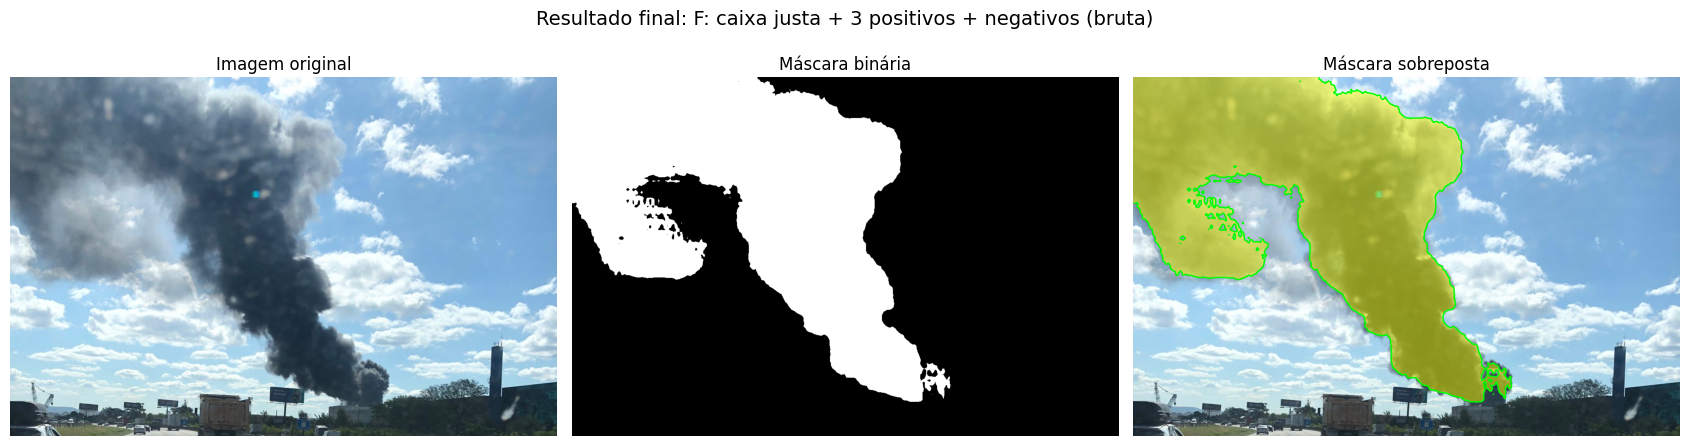

Arquivos salvos em resultados_segmentacao_pluma


In [36]:
for key in CONFIGS:
    Image.fromarray(masks_raw[key].astype(np.uint8) * 255).save(os.path.join(RESULTS_DIR, f"mascara_{key}_bruta.png"))
    Image.fromarray(masks_ref[key].astype(np.uint8) * 255).save(os.path.join(RESULTS_DIR, f"mascara_{key}_limpa.png"))

# figura final com o melhor resultado
final_key, final_var = best_idx
final_mask = (masks_raw if final_var == "bruta" else masks_ref)[final_key]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].imshow(image[:VIEW_Y]); axes[0].set_title("Imagem original")
axes[1].imshow(final_mask[:VIEW_Y], cmap="gray", vmin=0, vmax=1); axes[1].set_title("Máscara binária")
axes[2].imshow(image[:VIEW_Y])
axes[2].imshow(np.ma.masked_where(~final_mask[:VIEW_Y], final_mask[:VIEW_Y]), cmap="autumn", alpha=0.5, vmin=0, vmax=1)
axes[2].contour(final_mask[:VIEW_Y].astype(float), levels=[0.5], colors=["lime"], linewidths=1)
axes[2].set_title("Máscara sobreposta")
for a in axes: a.axis("off")
fig.suptitle(f"Resultado final: {CONFIGS[final_key]['label']} ({final_var})", fontsize=14)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "fig_final.png"), dpi=150, bbox_inches="tight"); plt.show()

print("Arquivos salvos em", RESULTS_DIR)